# Build the preprocessing feature tables

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from numpy.lib.stride_tricks import sliding_window_view
from scipy.linalg import eigh
from scipy.signal import fftconvolve, periodogram, welch
from tqdm import tqdm

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 180, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
pd.set_option("display.max_colwidth", 100)

## Configure the extraction

Set the window quality rules and feature parameters.

In [2]:
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "capslpdb" / "recordings.csv").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook inside the project directory.")
DATA_DIR = PROJECT_ROOT / "data" / "capslpdb"
SELECTION_FILE = PROJECT_ROOT / "outputs" / "01_data_quality" / "channel_selections.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "02_preprocessing"
FEATURE_DIR = OUTPUT_DIR / "features"
STAGING_DIR = OUTPUT_DIR / "staging"
FIGURE_DIR = OUTPUT_DIR / "figures"
CACHE_DIR = OUTPUT_DIR / "cache"
for directory in (FEATURE_DIR, STAGING_DIR / "clinical_features", FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
RECORD_IDS = None
MAX_WINDOWS_PER_RECORDING = None
EPOCH_SECONDS = 30
EEG_BANDS = {"delta": (0.5, 4.0), "theta": (4.0, 8.0), "alpha": (8.0, 13.0), "beta": (13.0, 30.0)}
EEG_POWER = "relative"
WELCH_SECONDS = 4
CENTER_EMG = True
CLIPPING_REJECT_FRACTION = 0.01
FLAT_STEP_REJECT_FRACTION = 0.995
AMPLITUDE_FLAG_UV = {"eeg": 1000.0, "eog": 1500.0, "emg": 5000.0}
INCLUDE_FLAGGED_WINDOWS = True
RUN_SSA = False
SSA_LAG_SECONDS = 0.5
SSA_MIN_BAND_FRACTION = 0.6
CHANNEL_CANDIDATES = {
    "eeg": [("C4-A1",)],
    "eog": [("ROC-LOC",)],
    "emg": [("EMG1-EMG2",)],
}
FEATURE_COLUMNS = ["eeg_delta_power", "eeg_theta_power", "eeg_alpha_power", "eeg_beta_power", "eog_sd_uv", "emg_rms_uv"]
RECORDING_FEATURE_COLUMNS = [f"{feature}_{statistic}" for feature in FEATURE_COLUMNS for statistic in ("median", "p90")]
HYPNOGRAM_STAGES = {"SLEEP-S0": "W", "SLEEP-S1": "S1", "SLEEP-S2": "S2", "SLEEP-S3": "S3", "SLEEP-S4": "S4", "SLEEP-REM": "R", "SLEEP-MT": "MT"}
MIN_REM_WINDOWS = 10
REM_FEATURE_COLUMNS = [f"{feature}_rem_{statistic}" for feature in FEATURE_COLUMNS for statistic in ("median", "p90")]
NREM_STAGES = {"S2", "S3", "S4"}
RATIO_FEATURE_COLUMNS = ["emg_rem_nrem_ratio_median", "emg_rem_nrem_ratio_p90"]
MINI_EPOCH_SECONDS = 3
EMG_BACKGROUND_STAGES = {"S1", "S2", "S3", "S4", "R"}
EMG_BACKGROUND_QUANTILE = 0.10
EMG_ACTIVITY_FACTOR = 2.0
TONIC_MIN_FRACTION = 0.5
MINI_EPOCH_COLUMNS = [f"emg_rms_uv_3s_{index:02d}" for index in range(int(EPOCH_SECONDS // MINI_EPOCH_SECONDS))]
ACTIVITY_FEATURE_COLUMNS = ["emg_rem_active_fraction", "emg_rem_tonic_fraction"]
# "ensemble" (mean of YASA and GSSC), "yasa", "gssc" or "manual" (scoring files).
STAGING = "ensemble"
# "scored": sleep architecture from lights off to lights on, like the manual scoring. "recording": whole EDF.
STAGING_PERIOD = "scored"
STAGING_SFREQ = 100
if MINI_EPOCH_SECONDS <= 0 or EPOCH_SECONDS % MINI_EPOCH_SECONDS:
    raise ValueError("MINI_EPOCH_SECONDS must divide EPOCH_SECONDS.")
if not 0 < EMG_BACKGROUND_QUANTILE < 1 or EMG_ACTIVITY_FACTOR <= 1 or not 0 <= TONIC_MIN_FRACTION < 1:
    raise ValueError("Invalid EMG activity settings.")
if STAGING not in {"yasa", "gssc", "ensemble", "manual"}:
    raise ValueError("STAGING must be yasa, gssc, ensemble or manual.")
if STAGING_PERIOD not in {"scored", "recording"}:
    raise ValueError("STAGING_PERIOD must be scored or recording.")
if MIN_REM_WINDOWS < 1:
    raise ValueError("MIN_REM_WINDOWS must be positive.")
if any(low < 0 or high <= low for low, high in EEG_BANDS.values()):
    raise ValueError("EEG bands must have nonnegative, increasing bounds.")
if not 0 <= FLAT_STEP_REJECT_FRACTION <= 1 or any(value <= 0 for value in AMPLITUDE_FLAG_UV.values()):
    raise ValueError("Invalid flatness or amplitude thresholds.")
if EEG_POWER not in {"absolute", "relative"}:
    raise ValueError("EEG_POWER must be absolute or relative.")
if EPOCH_SECONDS <= 0 or WELCH_SECONDS > EPOCH_SECONDS:
    raise ValueError("Invalid window configuration.")
if not 0 <= CLIPPING_REJECT_FRACTION <= 1 or not 0 <= SSA_MIN_BAND_FRACTION <= 1:
    raise ValueError("Quality and SSA fractions must be between zero and one.")
if MAX_WINDOWS_PER_RECORDING is not None and MAX_WINDOWS_PER_RECORDING < 1:
    raise ValueError("MAX_WINDOWS_PER_RECORDING must be positive or None.")
if any(next_low != high for (_, high), (next_low, _) in zip(EEG_BANDS.values(), list(EEG_BANDS.values())[1:])):
    raise ValueError("The EEG bands must be contiguous.")
display(pd.DataFrame([
    {"Modality": "EEG", "Feature": name + " power", "Definition": f"{low:g}–{high:g} Hz; {EEG_POWER} power"}
    for name, (low, high) in EEG_BANDS.items()
] + [
    {"Modality": "EOG", "Feature": "Standard deviation", "Definition": "Population SD in µV"},
    {"Modality": "EMG", "Feature": "RMS", "Definition": "DC-centered RMS in µV" if CENTER_EMG else "Uncentered RMS in µV"},
]))
FEATURE_SETTINGS = {name: value for name, value in globals().items()
                    if name.isupper() and not name.startswith("STAGING") and not isinstance(value, Path)}


,Modality,Feature,Definition
0,EEG,delta power,0.5–4 Hz; relative power
1,EEG,theta power,4–8 Hz; relative power
2,EEG,alpha power,8–13 Hz; relative power
3,EEG,beta power,13–30 Hz; relative power
4,EOG,Standard deviation,Population SD in µV
5,EMG,RMS,DC-centered RMS in µV


## Read the channel selections

In [3]:
mapping = pd.read_csv(DATA_DIR / "recordings.csv", dtype=str)
if not SELECTION_FILE.is_file():
    raise FileNotFoundError("Run notebook 01 to create channel_selections.csv.")
channel_selections = pd.read_csv(SELECTION_FILE, dtype=str).fillna("")
required = {"record_id", "class_name", "original_edf", "selected_edf", "status"}
required.update(f"{modality}_{field}" for modality in CHANNEL_CANDIDATES for field in ("indices", "channels", "units"))
if not required.issubset(channel_selections.columns) or channel_selections["record_id"].duplicated().any():
    raise ValueError("The channel selection CSV is incomplete or contains duplicate recordings. Run notebook 01 again.")
if set(mapping["record_id"]) != set(channel_selections["record_id"]):
    raise ValueError("The channel selection CSV does not match the recordings list. Run notebook 01 again.")
mapping = mapping.merge(channel_selections, on="record_id", validate="one_to_one", suffixes=("", "_selection"))
if not mapping["class_name"].eq(mapping["class_name_selection"]).all() or not mapping["edf_path"].eq(mapping["original_edf"]).all():
    raise ValueError("Recording metadata changed. Run notebook 01 again.")
unresolved = mapping.loc[~mapping["status"].isin(["selected", "excluded"]), "record_id"]
if not unresolved.empty:
    raise ValueError(f"Channel selections need review: {', '.join(unresolved)}")
display(mapping.loc[mapping["status"].eq("excluded"), ["record_id", "class_name", "issues"]])
mapping = mapping.loc[mapping["status"].eq("selected")].copy()
if RECORD_IDS is not None:
    missing_ids = set(RECORD_IDS) - set(mapping["record_id"])
    if missing_ids:
        raise ValueError(f"Unknown or excluded recording identifiers: {sorted(missing_ids)}")
    mapping = mapping[mapping["record_id"].isin(RECORD_IDS)].copy()
if mapping.empty:
    raise ValueError("No recordings were selected.")
mapping["edf_path"] = mapping["selected_edf"]
mapping = mapping.sort_values("record_id").reset_index(drop=True)
selections = mapping.set_index("record_id")

def recording_path(relative_path):
    path = (DATA_DIR / relative_path).resolve()
    if not path.is_relative_to(DATA_DIR.resolve()):
        raise ValueError("The recording path leaves the dataset directory.")
    return path

display(mapping.groupby("class_name").size().rename("recordings").to_frame())

,record_id,class_name,issues
0,brux1,other,Incomplete EDF data blocks and inconsistent recording length
17,n16,healthy,No EOG or EMG channels in the EDF header


,recordings
class_name,
healthy,15
other,69
rbd,22


## Read EDF signals at their native rates

In [4]:
import sys
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
import edf_quality
import result_cache
from edf_quality import inspect_recordings, resolve_channel as _resolve_channel, read_montage, assess_window as _assess_window

def resolve_channel(edf, record_id, modality):
    row = selections.loc[record_id]
    indices = tuple(int(index) for index in row[f"{modality}_indices"].split(","))
    override = {record_id: {modality: indices}}
    selection = _resolve_channel(edf, record_id, modality, override, CHANNEL_CANDIDATES, EPOCH_SECONDS, EEG_BANDS)
    if selection is None:
        raise ValueError(f"The selected {modality.upper()} channel was not found.")
    actual = " minus ".join(f"{label} [index {index}]" for label, index in zip(selection["labels"], selection["indices"]))
    units = ", ".join(edf.units[index] for index in indices)
    if actual != row[f"{modality}_channels"] or units != row[f"{modality}_units"]:
        raise ValueError(f"The selected {modality.upper()} channel or unit changed. Run notebook 01 again.")
    return selection

def assess_window(values, clipped, modality):
    return _assess_window(values, clipped, modality, FLAT_STEP_REJECT_FRACTION, CLIPPING_REJECT_FRACTION, AMPLITUDE_FLAG_UV)

## Check the selected channels

Check the selected indices, labels and units against each EDF header.

In [5]:
headers, plans, inventory = inspect_recordings(mapping, recording_path, CHANNEL_CANDIDATES, resolve_channel)
display(pd.crosstab(inventory["class_name"], inventory["status"]))
display(inventory.loc[inventory["status"].ne("ready"), ["record_id", "class_name", "status", "reason"]])
if not plans:
    raise ValueError("No recordings have a complete valid channel mapping.")

Inspect EDF headers: 100%|██████████| 106/106 [00:00<00:00, 1157.69record/s]


status,ready
class_name,
healthy,15
other,69
rbd,22


,record_id,class_name,status,reason


## Read the hypnograms

Assign the manually scored stage of the scoring file (`.txt`) to each 30-second window.

In [6]:
import re
from functools import lru_cache

if "txt_path" not in mapping.columns:
    raise ValueError("recordings.csv has no txt_path column. Run scripts/organize_data.py again.")
CLOCK_TIME = re.compile(r"(\d{1,2})[:.](\d{2})[:.](\d{2})")

def clock_seconds(text):
    match = CLOCK_TIME.fullmatch(text.strip())
    if match is None:
        raise ValueError(f"Invalid clock time: {text!r}")
    hours, minutes, seconds = map(int, match.groups())
    if hours > 23 or minutes > 59 or seconds > 59:
        raise ValueError(f"Invalid clock time: {text!r}")
    return hours * 3600 + minutes * 60 + seconds

def edf_start_seconds(path):
    with Path(path).open("rb") as stream:
        header = stream.read(184)
    if len(header) < 184:
        raise ValueError("The EDF header is incomplete.")
    return clock_seconds(header[176:184].decode("ascii", "replace"))

def table_fields(line):
    line = line.rstrip("\r\n")
    return [field.strip() for field in (line.split("\t") if "\t" in line else re.split(r" {2,}", line.strip()))]

@lru_cache(maxsize=None)
def read_scoring_table(path):
    lines = Path(path).read_text(encoding="latin-1").splitlines()
    header_row = next((index for index, line in enumerate(lines)
                       if "time" in line.lower() and "event" in line.lower()), None)
    if header_row is None:
        raise ValueError("The scoring file has no table header with Time and Event columns.")
    return table_fields(lines[header_row]), lines[header_row + 1:]

def read_hypnogram(path):
    """Return the sleep-stage events of a CAP scoring file with continuous clock times in seconds."""
    header, lines = read_scoring_table(path)
    header = [name.lower() for name in header]
    def column(prefix):
        matches = [index for index, name in enumerate(header) if name.startswith(prefix)]
        if len(matches) != 1:
            raise ValueError(f"The scoring table needs exactly one {prefix} column.")
        return matches[0]
    time_column, event_column, duration_column = column("time"), column("event"), column("duration")
    rows, previous, day, unknown = [], None, 0, set()
    for line in lines:
        fields = table_fields(line)
        if len(fields) <= max(time_column, event_column) or not fields[event_column].upper().startswith("SLEEP-"):
            continue
        event = fields[event_column].upper()
        clock = clock_seconds(fields[time_column])
        if previous is not None and clock < previous - 12 * 3600:
            day += 1
        previous = clock
        duration = fields[duration_column] if len(fields) > duration_column else ""
        if event not in HYPNOGRAM_STAGES:
            unknown.add(event)
        rows.append({"clock": clock + day * 86400, "duration": float(duration) if duration else float(EPOCH_SECONDS),
                     "stage": HYPNOGRAM_STAGES.get(event, "unscored")})
    if not rows:
        raise ValueError("The scoring file contains no sleep-stage events.")
    epochs = pd.DataFrame(rows)
    if (epochs["duration"] <= 0).any():
        raise ValueError("The scoring file contains non-positive durations.")
    return epochs, sorted(unknown)

def window_stages(epochs, start_seconds, window_count):
    clock = epochs["clock"].to_numpy(dtype=float)
    first = (clock[0] - start_seconds + 12 * 3600) % 86400 - 12 * 3600
    onsets = clock - clock[0] + first
    order = np.argsort(onsets, kind="stable")
    onsets, ends = onsets[order], (onsets + epochs["duration"].to_numpy(dtype=float))[order]
    labels = epochs["stage"].to_numpy(dtype=object)[order]
    midpoints = (np.arange(window_count) + 0.5) * EPOCH_SECONDS
    position = np.clip(np.searchsorted(onsets, midpoints, side="right") - 1, 0, None)
    covered = (midpoints >= onsets[position]) & (midpoints < ends[position])
    return np.where(covered, labels[position], "unscored"), first

manual_stage_labels, hypnogram_rows = {}, []
for record in tqdm(mapping.to_dict("records"), desc="Read hypnograms", unit="record"):
    record_id = record["record_id"]
    if record_id not in plans:
        continue
    edf = headers[record_id]
    window_count = int(np.floor(edf.duration / EPOCH_SECONDS))
    row = {"record_id": record_id, "class_name": record["class_name"], "scoring_offset_seconds": np.nan,
           "grid_offset_seconds": np.nan, "scored_fraction": np.nan, "rem_windows": np.nan, "rem_minutes": np.nan, "issue": ""}
    try:
        epochs, unknown = read_hypnogram(recording_path(record["txt_path"]))
        labels, offset = window_stages(epochs, edf_start_seconds(edf.path), window_count)
        rem_windows = int(np.sum(labels == "R"))
        row.update({"scoring_offset_seconds": offset, "grid_offset_seconds": offset % EPOCH_SECONDS,
                    "scored_fraction": float(np.mean(labels != "unscored")), "rem_windows": rem_windows,
                    "rem_minutes": rem_windows * EPOCH_SECONDS / 60,
                    "issue": f"Unknown stage events: {', '.join(unknown)}" if unknown else ""})
    except (OSError, ValueError, UnicodeDecodeError) as exc:
        labels = np.full(window_count, "unscored", dtype=object)
        row["issue"] = f"{type(exc).__name__}: {exc}"
    manual_stage_labels[record_id] = labels
    hypnogram_rows.append(row)

window_stage_labels = dict(manual_stage_labels)
hypnograms = pd.DataFrame(hypnogram_rows)
display(hypnograms.groupby("class_name").agg(
    recordings=("record_id", "size"), median_scored_fraction=("scored_fraction", "median"),
    median_rem_minutes=("rem_minutes", "median"),
    below_min_rem=("rem_windows", lambda values: int((values.fillna(0) < MIN_REM_WINDOWS).sum())),
    failed=("issue", lambda values: int(values.str.contains("Error").sum()))).round(3))
needs_review = hypnograms.loc[hypnograms["issue"].ne("") | hypnograms["scored_fraction"].lt(0.9)
                              | hypnograms["grid_offset_seconds"].ne(0) | hypnograms["rem_windows"].fillna(0).lt(MIN_REM_WINDOWS)]
display(needs_review.round(3).reset_index(drop=True))

Read hypnograms: 100%|██████████| 106/106 [00:00<00:00, 340.79record/s]


,recordings,median_scored_fraction,median_rem_minutes,below_min_rem,failed
class_name,,,,,
healthy,15,0.977,107.50,0,0
other,69,0.956,84.50,0,0
rbd,22,0.989,70.75,0,0


,record_id,class_name,scoring_offset_seconds,grid_offset_seconds,scored_fraction,rem_windows,rem_minutes,issue
0,ins1,other,15870.0,0.0,0.566,133,66.5,
1,ins2,other,1.0,1.0,1.000,233,116.5,
2,ins3,other,4900.0,10.0,0.831,133,66.5,
3,ins4,other,12390.0,0.0,0.564,150,75.0,
4,ins6,other,13820.0,20.0,0.657,88,44.0,
5,ins8,other,1590.0,0.0,0.833,77,38.5,
6,n10,healthy,3600.0,0.0,0.869,215,107.5,
7,n2,healthy,11220.0,0.0,0.680,151,75.5,
8,n4,healthy,1710.0,0.0,0.822,198,99.0,
9,narco4,other,120.0,0.0,0.776,239,119.5,


## Score the sleep stages automatically

Score each window from the EEG and EOG with YASA and GSSC and average their probabilities for the ensemble.

In [7]:
from importlib.metadata import version

import sleep_staging

STAGING_CODE = result_cache.code_version(sleep_staging)

STAGE_LABELS = np.array(["W", "S1", "S2", "S3", "R"])
STAGING_MODALITIES = ["eeg", "eog"]
STAGERS = {"yasa": sleep_staging.yasa_probabilities, "gssc": sleep_staging.gssc_probabilities}

def staging_settings(record_id, stager):
    return {"stager": stager, "version": version(stager), "code": STAGING_CODE, "sfreq": STAGING_SFREQ,
            "edf": selections.loc[record_id, "selected_edf"],
            "channels": {modality: plans[record_id][modality]["labels"] for modality in STAGING_MODALITIES}}

@lru_cache(maxsize=1)
def staging_signals(record_id):
    edf, plan = headers[record_id], plans[record_id]
    with edf:
        return {modality: sleep_staging.resample(read_montage(edf, plan[modality])[0], plan[modality]["sfreq"], STAGING_SFREQ)
                for modality in STAGING_MODALITIES}

def stage_labels(probabilities):
    scored = ~np.isnan(probabilities).any(axis=1)
    labels = np.full(len(probabilities), "unscored", dtype=object)
    labels[scored] = STAGE_LABELS[probabilities[scored].argmax(axis=1)]
    return labels

stage_probabilities = {stager: {} for stager in STAGERS}
staging_issues, scored_now = [], dict.fromkeys(STAGERS, 0)
for record_id, manual in tqdm(manual_stage_labels.items(), desc="Score sleep stages", unit="record"):
    for stager, score in STAGERS.items():
        try:
            probabilities, loaded = result_cache.cached(
                CACHE_DIR / stager / f"{record_id}.pkl", staging_settings(record_id, stager),
                lambda: score(staging_signals(record_id)["eeg"], staging_signals(record_id)["eog"], STAGING_SFREQ))
            scored_now[stager] += not loaded
            if abs(len(probabilities) - len(manual)) > 1:
                raise ValueError(f"{len(probabilities)} epochs for {len(manual)} windows.")
        except (OSError, ValueError, RuntimeError) as exc:
            staging_issues.append({"record_id": record_id, "stager": stager, "issue": f"{type(exc).__name__}: {exc}"})
            continue
        aligned = np.full((len(manual), len(STAGE_LABELS)), np.nan)
        aligned[:min(len(probabilities), len(manual))] = probabilities[:len(manual)]
        stage_probabilities[stager][record_id] = aligned
if staging_issues:
    display(pd.DataFrame(staging_issues))
    raise RuntimeError("Automatic staging failed for the recordings above.")
stage_probabilities["ensemble"] = {record_id: (values + stage_probabilities["gssc"][record_id]) / 2
                                   for record_id, values in stage_probabilities["yasa"].items()}

tables = []
for record_id, manual in manual_stage_labels.items():
    table = pd.DataFrame({"record_id": record_id, "class_name": selections.loc[record_id, "class_name"],
                          "window_index": np.arange(len(manual)), "manual_stage": manual})
    for stager, records in stage_probabilities.items():
        values = records[record_id]
        table[f"{stager}_stage"] = stage_labels(values)
        table[f"{stager}_confidence"] = values.max(axis=1)
        for index, stage in enumerate(sleep_staging.STAGES):
            table[f"{stager}_p_{stage}"] = values[:, index]
    tables.append(table)
hypnogram_table = pd.concat(tables, ignore_index=True)
hypnogram_table.round(4).to_csv(STAGING_DIR / "hypnograms.csv", index=False)

stage_sets = {"manual": manual_stage_labels, **{stager: {record_id: stage_labels(values) for record_id, values in records.items()}
                                                for stager, records in stage_probabilities.items()}}
window_stage_labels = dict(stage_sets[STAGING])
display(pd.DataFrame({"scored now": scored_now, "loaded from cache": {stager: len(manual_stage_labels) - count
                                                                      for stager, count in scored_now.items()}})
        .rename_axis("stager"))
print(f"Features use the {STAGING} stages" + (", the mean of the YASA and GSSC probabilities." if STAGING == "ensemble" else "."))

Score sleep stages: 100%|██████████| 106/106 [06:30<00:00,  3.68s/record]


,scored now,loaded from cache
stager,,
yasa,106,0
gssc,106,0


Features use the ensemble stages, the mean of the YASA and GSSC probabilities.


## Compare the automatic and manual stages


----------------------------------------
Agreement with the manual scoring over all windows of each class (pooled)


recordings  windows  kappa  accuracy  rem_recall  \
stager   class_name                                                     
yasa     healthy             15    14919  0.792     0.851       0.835   
         other               69    69012  0.736     0.803       0.879   
         rbd                 22    22602  0.531     0.648       0.540   
         all                106   106533  0.701     0.777       0.807   
gssc     healthy             15    14915  0.778     0.842       0.791   
         other               69    68975  0.749     0.814       0.837   
         rbd                 22    22596  0.624     0.718       0.532   
         all                106   106486  0.727     0.798       0.771   
ensemble healthy             15    14915  0.798     0.856       0.822   
         other               69    68975  0.758     0.821       0.869   
         rbd                 22    22596  0.618     0.715       0.555   
         all                106   106486  0.734     0.803       0.801   

                     rem_precision  median_record_kappa  
stager   class_name                                      
yasa     healthy             0.926                0.810  
         other               0.867                0.745  
         rbd                 0.716                0.555  
         all                 0.855                0.739  
gssc     healthy             0.963                0.786  
         other               0.958                0.746  
         rbd                 0.923                0.652  
         all                 0.954                0.738  
ensemble healthy             0.955                0.793  
         other               0.945                0.760  
         rbd                 0.908                0.627  
         all                 0.942                0.749


----------------------------------------
Median REM minutes per recording


,ensemble,gssc,yasa,manual
class_name,,,,
healthy,92.5,87.5,98.0,107.5
other,80.0,74.5,90.5,84.5
rbd,43.0,39.2,55.0,70.8



----------------------------------------
Recall of each manual stage


manual                   W     N1     N2     N3      R
stager   class_name                                   
yasa     healthy     0.929  0.504  0.884  0.822  0.835
         other       0.951  0.400  0.835  0.662  0.879
         rbd         0.868  0.284  0.724  0.468  0.540
gssc     healthy     0.900  0.558  0.934  0.749  0.791
         other       0.970  0.504  0.879  0.634  0.837
         rbd         0.882  0.429  0.797  0.629  0.532
ensemble healthy     0.923  0.547  0.927  0.782  0.822
         other       0.972  0.476  0.881  0.642  0.869
         rbd         0.893  0.397  0.805  0.581  0.555


----------------------------------------
Agreement between YASA and GSSC on the manually scored windows: kappa = 0.802

----------------------------------------
Confusion matrix, rbd, ensemble (rows: manual, columns: automatic, row fractions)


ensemble,W,N1,N2,N3,R
manual,,,,,
W,0.893,0.049,0.053,0.000,0.004
N1,0.399,0.397,0.174,0.002,0.027
N2,0.085,0.059,0.805,0.031,0.019
N3,0.015,0.007,0.395,0.581,0.001
R,0.136,0.066,0.225,0.019,0.555



----------------------------------------
Confusion matrix, all, ensemble (rows: manual, columns: automatic, row fractions)


ensemble,W,N1,N2,N3,R
manual,,,,,
W,0.947,0.030,0.017,0.000,0.005
N1,0.341,0.465,0.139,0.001,0.054
N2,0.046,0.041,0.874,0.025,0.014
N3,0.015,0.002,0.333,0.649,0.001
R,0.053,0.044,0.098,0.004,0.801


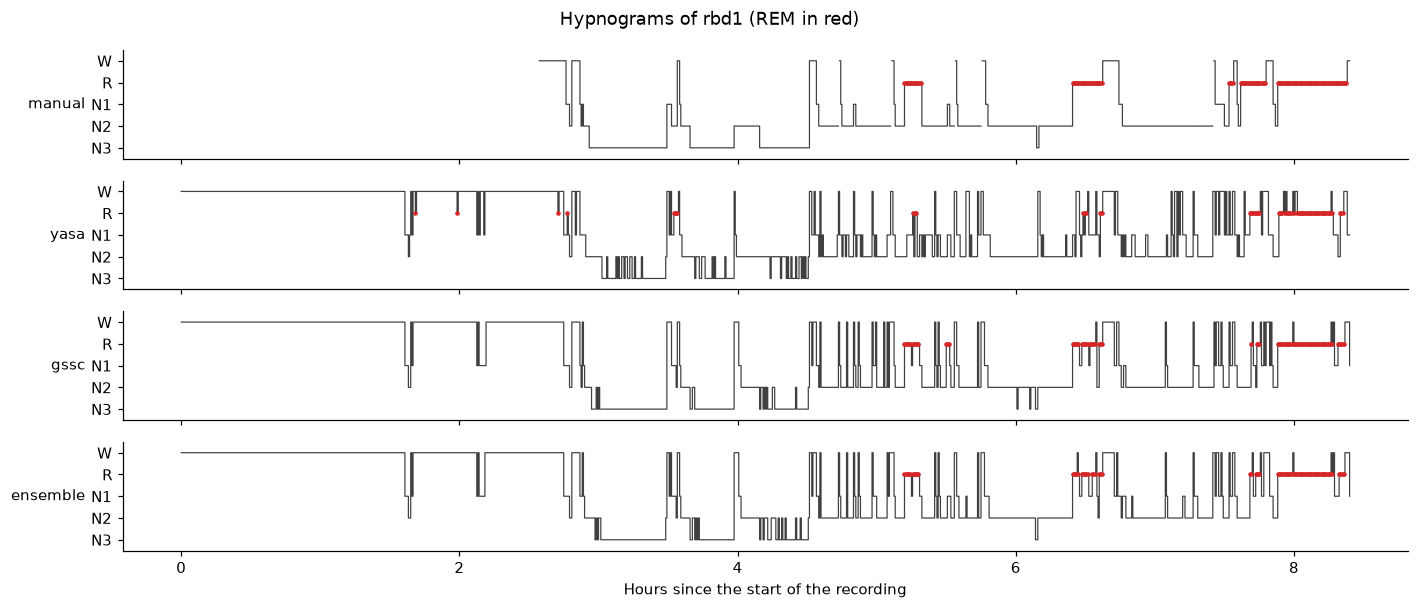

In [8]:
from sklearn.metrics import cohen_kappa_score

AASM_STAGES = {"W": "W", "S1": "N1", "S2": "N2", "S3": "N3", "S4": "N3", "R": "R"}
STAGE_ORDER = ["W", "N1", "N2", "N3", "R"]
compared_stagers = list(stage_probabilities)
compared = hypnogram_table.assign(manual=hypnogram_table["manual_stage"].map(AASM_STAGES)).dropna(subset=["manual"])
for stager in compared_stagers:
    compared[stager] = compared[f"{stager}_stage"].map(AASM_STAGES)

def agreement(group, stager):
    group = group.dropna(subset=[stager])
    manual_rem, auto_rem = group["manual"].eq("R"), group[stager].eq("R")
    both_rem = (manual_rem & auto_rem).sum()
    return {"windows": len(group),
            "kappa": cohen_kappa_score(group["manual"], group[stager], labels=STAGE_ORDER) if len(group) else np.nan,
            "accuracy": group["manual"].eq(group[stager]).mean(),
            "rem_recall": both_rem / manual_rem.sum() if manual_rem.any() else np.nan,
            "rem_precision": both_rem / auto_rem.sum() if auto_rem.any() else np.nan,
            "rem_minutes_manual": manual_rem.sum() * EPOCH_SECONDS / 60,
            "rem_minutes_auto": auto_rem.sum() * EPOCH_SECONDS / 60}

per_record = pd.DataFrame([{"stager": stager, "record_id": record_id, "class_name": group["class_name"].iloc[0],
                            **agreement(group, stager)}
                           for stager in compared_stagers for record_id, group in compared.groupby("record_id", sort=True)])
per_record.to_csv(STAGING_DIR / "staging_agreement.csv", index=False)
pooled = pd.DataFrame([{"stager": stager, "class_name": name, "recordings": group["record_id"].nunique(), **agreement(group, stager)}
                       for stager in compared_stagers
                       for name, group in [*compared.groupby("class_name", sort=True), ("all", compared)]])
median_kappa = pd.concat([per_record, per_record.assign(class_name="all")]).groupby(["stager", "class_name"])["kappa"].median()
pooled = pooled.set_index(["stager", "class_name"]).join(median_kappa.rename("median_record_kappa"))
print("\n" + "-" * 40)
print("Agreement with the manual scoring over all windows of each class (pooled)")
display(pooled.drop(columns=["rem_minutes_manual", "rem_minutes_auto"]).round(3))
print("\n" + "-" * 40)
print("Median REM minutes per recording")
display(per_record.pivot_table(index="class_name", columns="stager", values="rem_minutes_auto", aggfunc="median")
        .join(per_record.groupby("class_name")["rem_minutes_manual"].median().rename("manual")).round(1))
print("\n" + "-" * 40)
print("Recall of each manual stage")
display(pd.concat({stager: compared.dropna(subset=[stager]).assign(hit=lambda frame: frame["manual"].eq(frame[stager]))
                   .pivot_table(index="class_name", columns="manual", values="hit", aggfunc="mean")
                   .reindex(columns=STAGE_ORDER) for stager in compared_stagers}, names=["stager"]).round(3))
both = compared.dropna(subset=["yasa", "gssc"])
between = cohen_kappa_score(both["yasa"], both["gssc"], labels=STAGE_ORDER)
print("\n" + "-" * 40)
print(f"Agreement between YASA and GSSC on the manually scored windows: kappa = {between:.3f}")
staging_view = STAGING if STAGING != "manual" else compared_stagers[0]
for name in ["rbd", "all"]:
    subset = compared if name == "all" else compared.loc[compared["class_name"].eq(name)]
    subset = subset.dropna(subset=[staging_view])
    print("\n" + "-" * 40)
    print(f"Confusion matrix, {name}, {staging_view} (rows: manual, columns: automatic, row fractions)")
    display(pd.crosstab(subset["manual"], subset[staging_view], normalize="index")
            .reindex(index=STAGE_ORDER, columns=STAGE_ORDER, fill_value=0).round(3))

example_id = "rbd1" if "rbd1" in manual_stage_labels else next(iter(manual_stage_labels))
example = hypnogram_table.loc[hypnogram_table["record_id"].eq(example_id)]
levels = {"W": 4, "R": 3, "N1": 2, "N2": 1, "N3": 0}
rows = ["manual", *compared_stagers]
figure, axes = plt.subplots(len(rows), 1, figsize=(13, 1.4 * len(rows)), sharex=True, squeeze=False)
hours = example["window_index"] * EPOCH_SECONDS / 3600
for axis, row in zip(axes[:, 0], rows):
    stages = example[f"{row}_stage"].map(AASM_STAGES).map(levels)
    axis.step(hours, stages, where="post", color="0.25", linewidth=0.8)
    axis.scatter(hours[stages.eq(3)], stages[stages.eq(3)], s=4, color="tab:red", zorder=3)
    axis.set_yticks(list(levels.values()), list(levels))
    axis.set_ylabel(row, rotation=0, ha="right", va="center")
    axis.set_ylim(-0.5, 4.5)
axes[-1, 0].set_xlabel("Hours since the start of the recording")
figure.suptitle(f"Hypnograms of {example_id} (REM in red)")
figure.tight_layout()
figure.savefig(FIGURE_DIR / "hypnogram_comparison.png", dpi=150)
plt.show()

## Define the optional EEG SSA comparison

Compare EEG features with an SSA reconstruction.

In [9]:
def ssa_eeg(values, sfreq):
    centered = np.asarray(values, dtype=float) - np.mean(values)
    lag = round(SSA_LAG_SECONDS * sfreq)
    if not 2 <= lag <= len(centered) // 2:
        raise ValueError("SSA lag must be between two samples and half the epoch length.")
    trajectory = np.ascontiguousarray(sliding_window_view(centered, lag).T)
    columns = trajectory.shape[1]
    eigenvalues, vectors = eigh(trajectory @ trajectory.T / columns, check_finite=False)
    eigenvalues, vectors = np.maximum(eigenvalues[::-1], 0), vectors[:, ::-1]
    frequencies, power = periodogram(vectors, fs=sfreq, window="boxcar", detrend=False, axis=0)
    ranges = [(0.0, next(iter(EEG_BANDS.values()))[0]), *EEG_BANDS.values(), (max(high for low, high in EEG_BANDS.values()), np.inf)]
    contributions = np.array([power[(frequencies >= low) & (frequencies < high)].sum(axis=0) for low, high in ranges])
    contributions /= np.maximum(power.sum(axis=0), np.finfo(float).tiny)
    assignment = np.argmax(contributions, axis=0)
    counts = np.convolve(np.ones(lag), np.ones(columns))
    groups = {}
    selected_counts = {}
    for group_number, band in enumerate(EEG_BANDS, start=1):
        selected = np.flatnonzero((assignment == group_number) & (contributions[group_number] >= SSA_MIN_BAND_FRACTION) & (eigenvalues > eigenvalues.max() * 1e-12))
        selected_counts[band] = int(len(selected))
        reconstructed = np.zeros(len(centered))
        if len(selected):
            scores = vectors[:, selected].T @ trajectory
            for row, index in enumerate(selected):
                reconstructed += fftconvolve(vectors[:, index], scores[row], mode="full") / counts
        groups[band] = reconstructed
    if not any(selected_counts.values()):
        raise ValueError("SSA retained no components under the configured frequency rule.")
    return np.sum(list(groups.values()), axis=0), groups, selected_counts

## Define the six numerical features

Integrate Welch power over fixed EEG bands and compute EOG SD and EMG RMS from their native samples.

In [10]:
def band_integral(frequencies, power, low, high):
    inside = (frequencies > low) & (frequencies < high)
    grid = np.r_[low, frequencies[inside], high]
    selected_power = np.r_[np.interp(low, frequencies, power), power[inside], np.interp(high, frequencies, power)]
    return float(np.trapezoid(selected_power, grid))

def eeg_features(values, sfreq):
    segment = min(len(values), round(WELCH_SECONDS * sfreq))
    frequencies, power = welch(values, fs=sfreq, window="hann", nperseg=segment, noverlap=segment // 2, detrend="constant", scaling="density")
    band_power = {f"eeg_{name}_power": band_integral(frequencies, power, low, high) for name, (low, high) in EEG_BANDS.items()}
    total = sum(band_power.values())
    if total <= 0 or not np.isfinite(total):
        raise ValueError("EEG band power is not positive and finite.")
    if EEG_POWER == "relative":
        band_power = {name: value / total for name, value in band_power.items()}
    return band_power

def extract_features(signals, rates, eeg_override=None):
    eeg = signals["eeg"] if eeg_override is None else eeg_override
    emg = signals["emg"] - np.mean(signals["emg"]) if CENTER_EMG else signals["emg"]
    features = {**eeg_features(eeg, rates["eeg"]), "eog_sd_uv": float(np.std(signals["eog"], ddof=0)), "emg_rms_uv": float(np.sqrt(np.mean(emg ** 2)))}
    if not np.isfinite(list(features.values())).all():
        raise ValueError("Feature extraction produced non-finite values.")
    return features

def emg_mini_epochs(values, sfreq):
    """RMS of the chin EMG in consecutive mini-epochs, each centered on its own mean."""
    samples = round(MINI_EPOCH_SECONDS * sfreq)
    if samples < 2 or samples * len(MINI_EPOCH_COLUMNS) > len(values):
        raise ValueError("The EMG window is too short for the mini-epochs.")
    pieces = np.asarray(values, dtype=float)[:samples * len(MINI_EPOCH_COLUMNS)].reshape(len(MINI_EPOCH_COLUMNS), samples)
    rms = np.sqrt(np.mean((pieces - pieces.mean(axis=1, keepdims=True)) ** 2, axis=1))
    if not np.isfinite(rms).all():
        raise ValueError("The EMG mini-epoch RMS is not finite.")
    return dict(zip(MINI_EPOCH_COLUMNS, rms.tolist()))

## Load one complete recording and process its windows

Process the 30-second windows of one recording.

In [11]:
def process_record(record, max_windows=None, use_ssa=None):
    record_id = record["record_id"]
    edf = headers[record_id]
    plan = plans[record_id]
    use_ssa = RUN_SSA if use_ssa is None else use_ssa
    full_windows = int(np.floor(edf.duration / EPOCH_SECONDS))
    count = min(full_windows, max_windows) if max_windows is not None else full_windows
    if count == 0:
        raise ValueError("Recording contains no complete epoch.")
    variants = {"baseline": []}
    if use_ssa:
        variants["ssa"] = []
    rates = {modality: selection["sfreq"] for modality, selection in plan.items()}
    with edf:
        loaded = {modality: read_montage(edf, selection) for modality, selection in plan.items()}
        header_exceeded = [f"{modality.upper()}: {edf.labels[index]}" for modality, selection in plan.items()
                           for index in selection["indices"] if not edf.digital_limits(index)[2]]
    header_exceeded = ", ".join(header_exceeded)
    loaded_megabytes = sum(values.nbytes + clipped.nbytes for values, clipped in loaded.values()) / 1024 ** 2
    samples_per_epoch = {modality: round(EPOCH_SECONDS * rates[modality]) for modality in plan}
    for index in range(count):
        signals = {modality: loaded[modality][0][index * samples:(index + 1) * samples] for modality, samples in samples_per_epoch.items()}
        clipping = {modality: loaded[modality][1][index * samples:(index + 1) * samples] for modality, samples in samples_per_epoch.items()}
        quality = {modality: assess_window(signals[modality], clipping[modality], modality) for modality in plan}
        rejections = [reason for item in quality.values() for reason in item["reject"]]
        flags = [reason for item in quality.values() for reason in item["flags"]]
        accepted = not rejections and (INCLUDE_FLAGGED_WINDOWS or not flags)
        base = {
            "record_id": record_id, "class_name": record["class_name"], "original_group": record["original_group"],
            "window_index": index, "start_seconds": index * EPOCH_SECONDS, "duration_seconds": EPOCH_SECONDS,
            "sleep_stage": window_stage_labels[record_id][index],
            "accepted": accepted, "quality_status": "exclude" if not accepted else ("flag" if flags else "keep"),
            "quality_reasons": ";".join(rejections + flags),
            "alternate_montage": any(selection["alternate"] for selection in plan.values()),
            "edf_path": record["edf_path"], "selection_issues": record["issues"], "header_range_exceeded": header_exceeded,
        }
        for modality in plan:
            base[f"{modality}_sfreq_hz"] = rates[modality]
            base[f"{modality}_channels"] = " minus ".join(plan[modality]["labels"])
            base[f"{modality}_ptp_uv"] = quality[modality]["ptp_uv"]
            base[f"{modality}_clipping_fraction"] = quality[modality]["clip_fraction"]
        for variant in variants:
            result = {**base, **dict.fromkeys(FEATURE_COLUMNS + MINI_EPOCH_COLUMNS, np.nan)}
            if accepted:
                try:
                    if variant == "ssa":
                        reconstructed, _, component_counts = ssa_eeg(signals["eeg"], rates["eeg"])
                        result.update(extract_features(signals, rates, eeg_override=reconstructed))
                        result.update({f"ssa_{band}_components": n for band, n in component_counts.items()})
                    else:
                        result.update(extract_features(signals, rates))
                    result.update(emg_mini_epochs(signals["emg"], rates["emg"]))
                except (ValueError, np.linalg.LinAlgError, FloatingPointError) as exc:
                    result.update({"accepted": False, "quality_status": "exclude", "quality_reasons": ";".join(filter(None, [base["quality_reasons"], f"{variant}_feature_error: {exc}"]))})
            variants[variant].append(result)
    info = {"record_id": record_id, "duration_seconds": edf.duration, "loaded_megabytes": loaded_megabytes, "complete_windows": full_windows, "processed_windows": count, "trailing_seconds": edf.duration - full_windows * EPOCH_SECONDS, "limited_run": count < full_windows, "header_range_exceeded": header_exceeded}
    return {name: pd.DataFrame(rows) for name, rows in variants.items()}, info

## Preview a window

Inspect the selected EEG, EOG and EMG signals and the EEG spectrum.

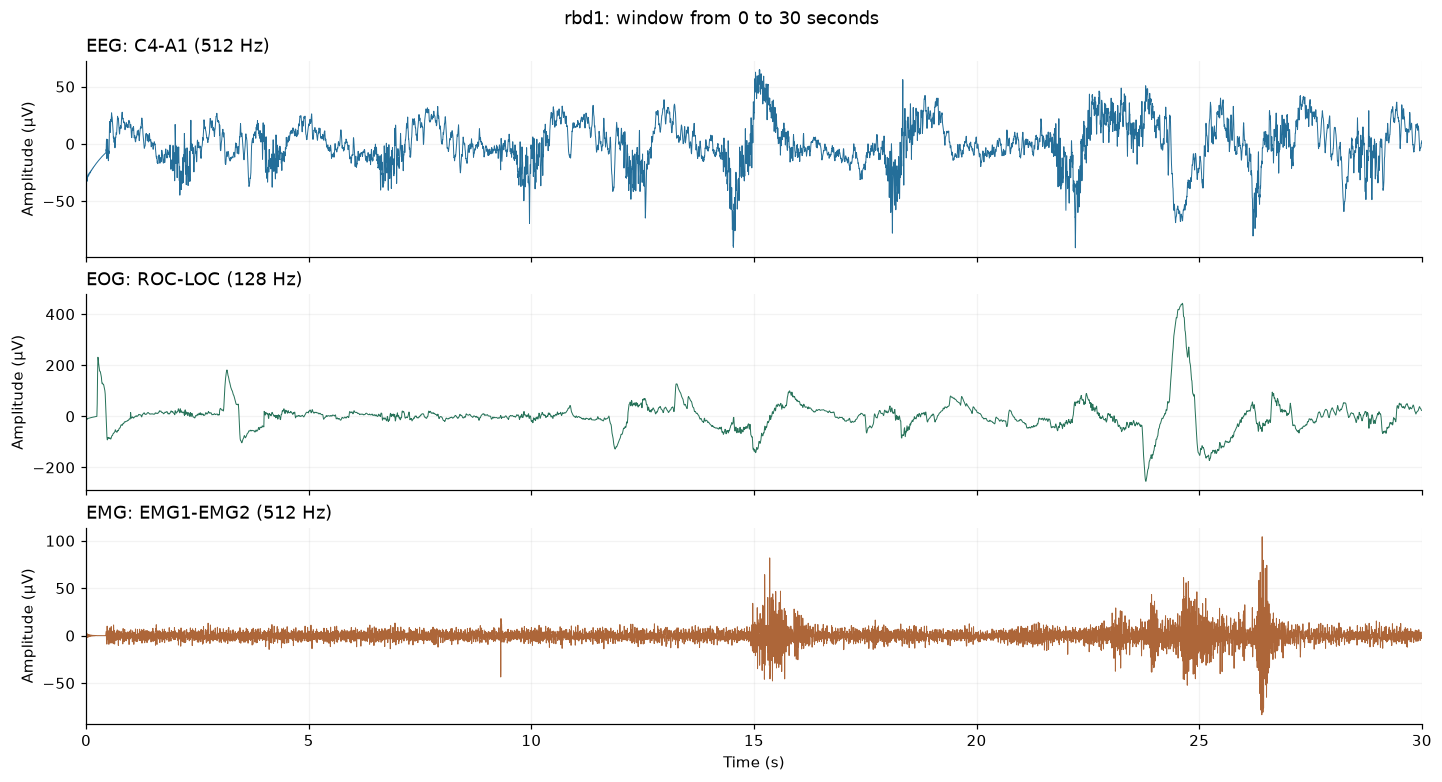

,reject,flags,ptp_uv,clip_fraction
eeg,[],[],155.433455,0.0
eog,[],[],696.69083,0.0
emg,[],[],187.637275,0.0


,eeg_delta_power,eeg_theta_power,eeg_alpha_power,eeg_beta_power,eog_sd_uv,emg_rms_uv
0,0.769825,0.113538,0.037531,0.079107,63.006713,7.535837


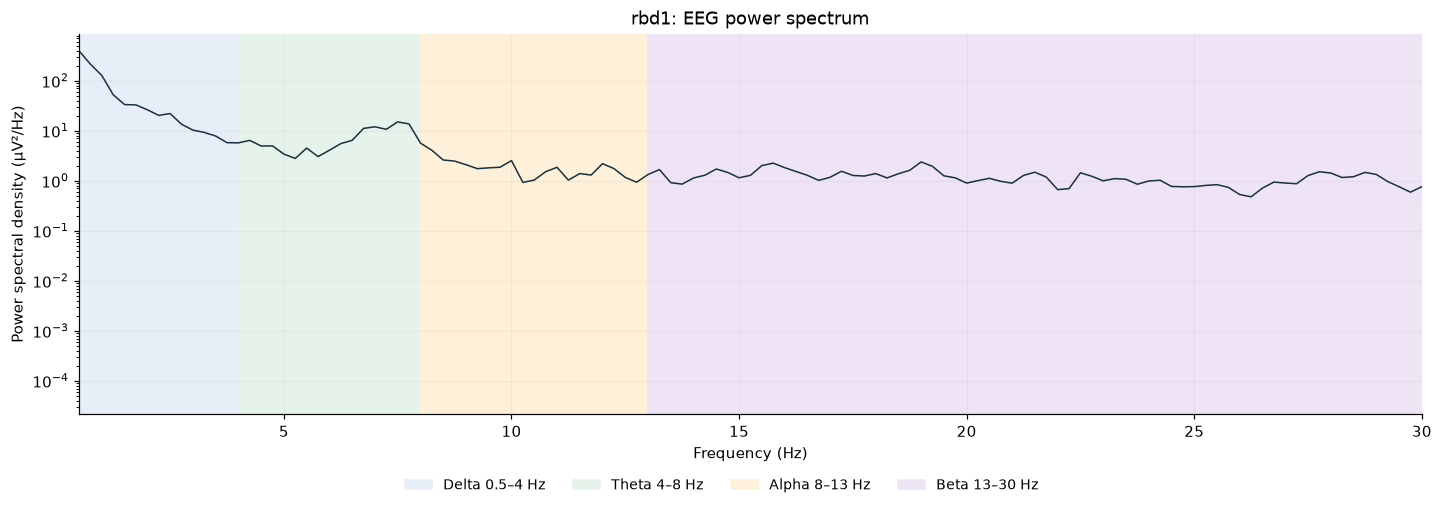

In [12]:
preview_id = "rbd1" if "rbd1" in plans else next(iter(plans))
preview_edf = headers[preview_id]
preview_plan = plans[preview_id]
preview_rates = {modality: selection["sfreq"] for modality, selection in preview_plan.items()}
preview_signals = None
with preview_edf:
    for preview_index in range(min(10, int(preview_edf.duration // EPOCH_SECONDS))):
        preview_blocks = {modality: read_montage(preview_edf, selection, preview_index * round(EPOCH_SECONDS * selection["sfreq"]), (preview_index + 1) * round(EPOCH_SECONDS * selection["sfreq"])) for modality, selection in preview_plan.items()}
        preview_signals = {modality: block[0] for modality, block in preview_blocks.items()}
        preview_qc = {modality: assess_window(preview_signals[modality], preview_blocks[modality][1], modality) for modality in preview_plan}
        if not any(item["reject"] for item in preview_qc.values()):
            break
if preview_signals is None:
    raise ValueError("No complete preview window exists.")
fig, axes = plt.subplots(3, 1, figsize=(13, 7), sharex=True, layout="constrained")
for ax, (modality, values), color in zip(axes, preview_signals.items(), ["#246e99", "#28735a", "#ad6639"]):
    time = np.arange(len(values)) / preview_rates[modality]
    ax.plot(time, values, color=color, linewidth=0.65)
    ax.set_title(f"{modality.upper()}: {' minus '.join(preview_plan[modality]['labels'])} ({preview_rates[modality]:g} Hz)", loc="left")
    ax.set_ylabel("Amplitude (µV)")
    ax.grid(alpha=0.15)
axes[-1].set(xlabel="Time (s)", xlim=(0, EPOCH_SECONDS))
fig.suptitle(f"{preview_id}: window from {preview_index * EPOCH_SECONDS:g} to {(preview_index + 1) * EPOCH_SECONDS:g} seconds")
fig.savefig(FIGURE_DIR / "preprocessing_signal_preview.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
preview_valid = not any(item["reject"] for item in preview_qc.values())
display(pd.DataFrame(preview_qc).T)
if preview_valid:
    display(pd.DataFrame([extract_features(preview_signals, preview_rates)]))
frequencies, power = welch(preview_signals["eeg"], fs=preview_rates["eeg"], window="hann", nperseg=round(WELCH_SECONDS * preview_rates["eeg"]), noverlap=round(WELCH_SECONDS * preview_rates["eeg"]) // 2, scaling="density")
fig, ax = plt.subplots(figsize=(13, 4.5), layout="constrained")
for (name, (low, high)), color in zip(EEG_BANDS.items(), ["#e7eef8", "#e6f3eb", "#fff0d9", "#eee4f6"]):
    ax.axvspan(low, high, color=color, label=f"{name.title()} {low:g}–{high:g} Hz")
ax.semilogy(frequencies, np.maximum(power, np.finfo(float).tiny), color="#19323f", linewidth=1)
ax.set(xlim=(0.5, 30), xlabel="Frequency (Hz)", ylabel="Power spectral density (µV²/Hz)", title=f"{preview_id}: EEG power spectrum")
ax.grid(alpha=0.15)
handles, legend_labels = ax.get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="outside lower center", ncols=4, fontsize=9)
fig.savefig(FIGURE_DIR / "preprocessing_eeg_spectrum.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
if RUN_SSA and preview_valid:
    preview_ssa, _, preview_counts = ssa_eeg(preview_signals["eeg"], preview_rates["eeg"])
    display(pd.DataFrame([preview_counts], index=["retained components"]))
    display(pd.DataFrame([extract_features(preview_signals, preview_rates, preview_ssa)], index=["SSA comparison"]))

## Extract all configured recordings

Extract features for each recording.

In [13]:
WINDOW_CODE = result_cache.code_version(process_record, extract_features, eeg_features, band_integral,
                                        emg_mini_epochs, ssa_eeg, assess_window, edf_quality)
frames = {name: [] for name in (["baseline", "ssa"] if RUN_SSA else ["baseline"])}
run_rows = []
for record in tqdm(mapping.to_dict("records"), desc="Extract recordings", unit="record"):
    record_id = record["record_id"]
    inventory_row = inventory.loc[inventory["record_id"].eq(record_id)].iloc[0]
    if record_id not in plans:
        run_rows.append({**record, "status": inventory_row["status"], "reason": inventory_row["reason"]})
        continue
    try:
        (current, info), _ = result_cache.cached(
            CACHE_DIR / "windows" / f"{record_id}.pkl", {"record": record, "settings": FEATURE_SETTINGS, "code": WINDOW_CODE},
            lambda: process_record(record, max_windows=MAX_WINDOWS_PER_RECORDING))
        for variant, table in current.items():
            frames[variant].append(table.assign(sleep_stage=window_stage_labels[record_id][table["window_index"].to_numpy()]))
        run_rows.append({**record, **info, "status": "processed", "reason": ""})
    except (OSError, ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
        run_rows.append({**record, "status": "processing_failed", "reason": f"{type(exc).__name__}: {exc}"})
run_report = pd.DataFrame(run_rows)
display(run_report.groupby(["class_name", "status"]).size().rename("recordings").to_frame())
failed = run_report.loc[run_report["status"].ne("processed"), ["record_id", "class_name", "status", "reason"]]
if not failed.empty:
    display(failed.reset_index(drop=True))
if not frames["baseline"]:
    raise RuntimeError("No recording was processed. Review the errors above.")
window_tables = {variant: pd.concat(tables, ignore_index=True) for variant, tables in frames.items()}

Extract recordings: 100%|██████████| 106/106 [02:12<00:00,  1.25s/record]


,,recordings
class_name,status,
healthy,processed,15
other,processed,69
rbd,processed,22


## Aggregate windows and export CSV files

Calculate the median and P90 of each feature for the whole recording and for REM sleep.

In [14]:
def summarize_recordings(windows):
    rows = []
    for record_id, all_windows in windows.groupby("record_id", sort=True):
        retained = all_windows.loc[all_windows["accepted"].eq(True)]
        if retained.empty:
            continue
        first = all_windows.iloc[0]
        row = {"record_id": record_id, "class_name": first["class_name"], "original_group": first["original_group"], "total_windows": len(all_windows), "retained_windows": len(retained), "rejected_windows": len(all_windows) - len(retained), "flagged_windows": int(all_windows["quality_status"].eq("flag").sum()), "retention_fraction": len(retained) / len(all_windows), "alternate_montage": bool(first["alternate_montage"]), "edf_path": first["edf_path"], "selection_issues": first["selection_issues"], "header_range_exceeded": first["header_range_exceeded"]}
        for modality in CHANNEL_CANDIDATES:
            row[f"{modality}_channels"] = first[f"{modality}_channels"]
        for feature in FEATURE_COLUMNS:
            values = retained[feature].to_numpy(dtype=float)
            row[f"{feature}_median"] = float(np.median(values))
            row[f"{feature}_p90"] = float(np.quantile(values, 0.90, method="linear"))
        rem = retained.loc[retained["sleep_stage"].eq("R")]
        row["scored_fraction"] = float(all_windows["sleep_stage"].ne("unscored").mean())
        row["rem_windows"] = len(rem)
        for feature in FEATURE_COLUMNS:
            values = rem[feature].to_numpy(dtype=float)
            enough = len(values) >= MIN_REM_WINDOWS
            row[f"{feature}_rem_median"] = float(np.median(values)) if enough else np.nan
            row[f"{feature}_rem_p90"] = float(np.quantile(values, 0.90, method="linear")) if enough else np.nan
        nrem_emg = retained.loc[retained["sleep_stage"].isin(NREM_STAGES), "emg_rms_uv"].to_numpy(dtype=float)
        row["nrem_windows"] = len(nrem_emg)
        for statistic, function in (("median", np.median), ("p90", lambda values: np.quantile(values, 0.90, method="linear"))):
            rem_value = row[f"emg_rms_uv_rem_{statistic}"]
            nrem_value = float(function(nrem_emg)) if len(nrem_emg) >= MIN_REM_WINDOWS else np.nan
            usable = np.isfinite(rem_value) and np.isfinite(nrem_value) and nrem_value > 0
            row[f"emg_rem_nrem_ratio_{statistic}"] = rem_value / nrem_value if usable else np.nan
        sleep_mini = retained.loc[retained["sleep_stage"].isin(EMG_BACKGROUND_STAGES), MINI_EPOCH_COLUMNS].to_numpy(dtype=float)
        rem_mini = rem[MINI_EPOCH_COLUMNS].to_numpy(dtype=float)
        background = float(np.quantile(sleep_mini, EMG_BACKGROUND_QUANTILE, method="linear")) if sleep_mini.size else np.nan
        if len(rem) >= MIN_REM_WINDOWS and np.isfinite(background) and background > 0:
            active = rem_mini > EMG_ACTIVITY_FACTOR * background
            row["emg_background_uv"] = background
            row["emg_rem_active_fraction"] = float(active.mean())
            row["emg_rem_tonic_fraction"] = float((active.mean(axis=1) > TONIC_MIN_FRACTION).mean())
        else:
            row.update(dict.fromkeys(["emg_background_uv", *ACTIVITY_FEATURE_COLUMNS], np.nan))
        rows.append(row)
    columns = ["record_id", "class_name", "original_group", "total_windows", "retained_windows", "rejected_windows", "flagged_windows", "retention_fraction", "alternate_montage", "edf_path", "selection_issues", "header_range_exceeded", "eeg_channels", "eog_channels", "emg_channels", *RECORDING_FEATURE_COLUMNS, "scored_fraction", "rem_windows", *REM_FEATURE_COLUMNS, "nrem_windows", *RATIO_FEATURE_COLUMNS, "emg_background_uv", *ACTIVITY_FEATURE_COLUMNS]
    return pd.DataFrame(rows, columns=columns)

exports = []
recording_tables = {}
for variant, windows in window_tables.items():
    if windows.duplicated(["record_id", "window_index"]).any():
        raise ValueError(f"Duplicate windows in {variant}.")
    valid = windows.loc[windows["accepted"].eq(True), FEATURE_COLUMNS]
    if not np.isfinite(valid.to_numpy(dtype=float)).all():
        raise ValueError(f"Accepted windows contain invalid features in {variant}.")
    if EEG_POWER == "relative" and len(valid):
        if not np.allclose(valid[FEATURE_COLUMNS[:4]].sum(axis=1), 1, atol=1e-8):
            raise ValueError("Relative EEG band powers do not sum to one.")
    recordings = summarize_recordings(windows)
    if recordings["record_id"].duplicated().any() or not np.isfinite(recordings[RECORDING_FEATURE_COLUMNS].to_numpy(dtype=float)).all():
        raise ValueError("Invalid recording feature table.")
    recording_tables[variant] = recordings
    if variant == "baseline":
        for name, table in [("features_windows.csv", windows.drop(columns=MINI_EPOCH_COLUMNS)), ("features_recordings.csv", recordings)]:
            destination = FEATURE_DIR / name
            temporary = destination.with_suffix(".tmp")
            table.to_csv(temporary, index=False, encoding="utf-8")
            temporary.replace(destination)
            exports.append({"file": name, "rows": len(table)})
print("\n" + "-" * 40)
print("Exported files")
display(pd.DataFrame(exports))
rem_coverage = recording_tables["baseline"].assign(has_rem_features=lambda table: table[REM_FEATURE_COLUMNS].notna().all(axis=1),
                                                    has_ratio=lambda table: table[RATIO_FEATURE_COLUMNS].notna().all(axis=1))
print("\n" + "-" * 40)
print("REM feature coverage")
display(rem_coverage.groupby("class_name").agg(recordings=("record_id", "size"), with_rem_features=("has_rem_features", "sum"),
                                                with_ratio=("has_ratio", "sum"), median_rem_windows=("rem_windows", "median"),
                                                median_nrem_windows=("nrem_windows", "median"),
                                                median_ratio=("emg_rem_nrem_ratio_median", "median"),
                                                median_active_fraction=("emg_rem_active_fraction", "median"),
                                                median_tonic_fraction=("emg_rem_tonic_fraction", "median")).round(3))
print("\n" + "-" * 40)
print("First recordings")
display(recording_tables["baseline"].head())


----------------------------------------
Exported files


,file,rows
0,features_windows.csv,118966
1,features_recordings.csv,106



----------------------------------------
REM feature coverage


,recordings,with_rem_features,with_ratio,median_rem_windows,median_nrem_windows,median_ratio,median_active_fraction,median_tonic_fraction
class_name,,,,,,,,
healthy,15,15,15,182.0,638.0,0.737,0.064,0.021
other,69,69,69,155.0,577.0,0.606,0.110,0.052
rbd,22,22,22,86.0,550.5,1.024,0.334,0.264



----------------------------------------
First recordings


,record_id,class_name,original_group,total_windows,retained_windows,rejected_windows,flagged_windows,retention_fraction,alternate_montage,edf_path,...,eog_sd_uv_rem_median,eog_sd_uv_rem_p90,emg_rms_uv_rem_median,emg_rms_uv_rem_p90,nrem_windows,emg_rem_nrem_ratio_median,emg_rem_nrem_ratio_p90,emg_background_uv,emg_rem_active_fraction,emg_rem_tonic_fraction
0,brux2,other,brux,1044,1044,0,3,1.000000,False,other/brux2/brux2.edf,...,18.094751,42.217048,1.161780,3.217042,511,0.539004,0.876188,0.980960,0.070745,0.015957
1,ins1,other,ins,1600,1600,0,16,1.000000,False,other/ins1/ins1.edf,...,28.110145,61.133402,0.693929,1.191539,542,0.499627,0.535487,0.599090,0.079433,0.007092
2,ins2,other,ins,1675,1675,0,0,1.000000,False,other/ins2/ins2.edf,...,8.139138,16.838163,1.093417,1.382388,567,0.606328,0.497051,1.004565,0.019731,0.000000
3,ins3,other,ins,1030,1030,0,1,1.000000,False,other/ins3/ins3.edf,...,12.366465,24.465670,1.469735,2.350152,261,0.708886,0.422555,1.126664,0.061594,0.021739
4,ins4,other,ins,1273,1271,2,38,0.998429,False,other/ins4/ins4.edf,...,17.927562,44.113508,1.063400,2.509881,521,0.317521,0.434963,0.844292,0.050427,0.000000


## Extract clinical features

The EDF headers of n13, n14 and n15 contain no units, so notebook 01 assumes microvolts and uses CHIN1 minus CHIN2 as their chin EMG.

In [15]:
from scipy.ndimage import minimum_filter1d
from scipy.signal import butter, sosfiltfilt
from edf_quality import NativeEDF

EMG_BAND_HZ = (10.0, 45.0)
STAGE_EVENTS = {'SLEEP-S0': 'W', 'SLEEP-S1': 'S1', 'SLEEP-S2': 'S2', 'SLEEP-S3': 'S3',
                'SLEEP-S4': 'S4', 'SLEEP-REM': 'R', 'SLEEP-MT': 'MT', 'SLEEP-UNSCORED': 'U', 'SLEEP-N': 'U'}
recordings = mapping.set_index('record_id')
windows = window_tables['baseline']
FEATURE_FILE = FEATURE_DIR / 'clinical_features.csv'

def read_events(path):
    header, lines = read_scoring_table(path)
    rows = [dict(zip(header, line.split("\t"))) for line in lines
            if line.strip() and len(line.split("\t")) >= len(header) - 1]
    events = pd.DataFrame(rows, columns=header)
    time_column = next(name for name in header if name.startswith("Time"))
    duration_column = next(name for name in header if name.startswith("Duration"))
    clock = pd.to_timedelta(events[time_column].str.strip().str.replace(".", ":", regex=False)).dt.total_seconds().to_numpy()
    seconds, offset = clock.copy(), 0.0
    for index in range(1, len(clock)):
        if clock[index] + offset < seconds[index - 1] - 6 * 3600:
            offset += 86400
        seconds[index] = clock[index] + offset
    events["onset"] = seconds - seconds[0]
    events["duration"] = pd.to_numeric(events[duration_column], errors="coerce").fillna(0)
    events["event"] = events["Event"].str.strip()
    return events[["onset", "duration", "event"]]

def manual_epochs(events):
    stages = events.loc[events["event"].isin(STAGE_EVENTS)].sort_values("onset")
    epochs = pd.Series([STAGE_EVENTS[event] for event, duration in zip(stages["event"], stages["duration"])
                        for _ in range(max(1, int(round(duration / 30))))])
    return epochs[epochs.ne("U")].reset_index(drop=True)

def stage_epochs(record_id, events, staging):
    if staging == "manual":
        return manual_epochs(events)
    epochs = pd.Series(stage_sets[staging][record_id], dtype=object)
    if STAGING_PERIOD == "scored":
        scored = np.flatnonzero(manual_stage_labels[record_id] != "unscored")
        if not len(scored):
            raise ValueError("The scoring file covers no window.")
        epochs = epochs.iloc[scored[0]:scored[-1] + 1]
    return epochs[epochs.ne("unscored")].reset_index(drop=True)

def architecture_features(epochs):
    asleep = epochs.isin(["S1", "S2", "S3", "S4", "R"])
    if not asleep.any():
        raise ValueError("The hypnogram contains no sleep.")
    total_sleep = asleep.sum() / 2
    onset, end = asleep.idxmax(), asleep[::-1].idxmax()
    sleep_period = epochs.iloc[onset:end + 1]
    transitions = sleep_period[sleep_period.ne(sleep_period.shift())]
    slow_wave = epochs.isin(["S3", "S4"])
    return {"sleep_efficiency": total_sleep / (len(epochs) / 2),
            "waso_min": (sleep_period == "W").sum() / 2,
            "awakenings_per_h": (transitions == "W").sum() / (total_sleep / 60),
            "stage_shifts_per_h": (len(transitions) - 1) / (len(sleep_period) / 120),
            "pct_rem": (epochs == "R").sum() / 2 / total_sleep,
            "sws_first_half": slow_wave.iloc[:len(epochs) // 2].sum() / max(1, slow_wave.sum())}

def cap_features(events):
    nrem_hours = events.loc[events["event"].isin(["SLEEP-S1", "SLEEP-S2", "SLEEP-S3", "SLEEP-S4"]), "duration"].sum() / 3600
    phases = events.loc[events["event"].str.startswith("MCAP-A")]
    onsets = np.sort(phases["onset"].to_numpy())
    cap_seconds, start = 0.0, 0
    for index in range(1, len(onsets) + 1):
        if index == len(onsets) or onsets[index] - onsets[index - 1] > 62:
            if index - start >= 3:
                cap_seconds += onsets[index - 1] - onsets[start] + 30
            start = index
    return {"cap_rate": cap_seconds / 3600 / nrem_hours,
            "cap_a_index": len(phases) / nrem_hours,
            "cap_a3_index": phases["event"].eq("MCAP-A3").sum() / nrem_hours,
            "cap_a1_share": phases["event"].eq("MCAP-A1").mean() if len(phases) else np.nan}

In [16]:
def window_features(table):
    accepted = table.loc[table["accepted"]]
    rem = accepted.loc[accepted["sleep_stage"].eq("R")]
    stage_2 = accepted.loc[accepted["sleep_stage"].eq("S2")]
    slow_wave = accepted.loc[accepted["sleep_stage"].isin(["S3", "S4"])]
    return {"sws_delta": slow_wave["eeg_delta_power"].median(),
            "s2_emg_sd": np.log(stage_2["emg_rms_uv"].clip(lower=1e-3)).std(),
            "rem_theta_alpha": np.log(rem["eeg_theta_power"].median() / rem["eeg_alpha_power"].median())}

In [17]:
def mini_epoch_activity(rms_1s, rms_3s, amplitude, background):
    local_floor = rms_1s.min(axis=1, keepdims=True)
    low, middle = (amplitude <= 1).mean(), ((amplitude > 1) & (amplitude <= 2)).mean()
    return {"phasic_1s": (rms_1s > 3 * local_floor).mean(),
            "tonic": ((rms_1s > 2 * background).mean(axis=1) >= 0.5).mean(),
            "any_3s": (rms_3s > 2 * background).any(axis=1).mean(),
            "atonia_index": low / max(1e-6, 1 - middle),
            "log_rms_p90": np.log(np.quantile(rms_1s, 0.9) / background)}

def read_emg_seconds(record_id):
    selection = selections.loc[record_id]
    indices = [int(index) for index in str(selection["emg_indices"]).split(",")]
    edf = NativeEDF(DATA_DIR / selection["selected_edf"])
    rate = edf.sfreq(indices[0])
    with edf:
        emg, _ = read_montage(edf, {"indices": indices})
    sos = butter(4, [EMG_BAND_HZ[0], min(EMG_BAND_HZ[1], 0.45 * rate)], btype="bandpass", fs=rate, output="sos")
    emg = sosfiltfilt(sos, emg - emg.mean())
    samples = int(round(rate))
    seconds = emg[:len(emg) // samples * samples].reshape(-1, samples)
    amplitude = np.abs(seconds).mean(axis=1)
    return np.sqrt((seconds ** 2).mean(axis=1)), amplitude - minimum_filter1d(amplitude, 61, mode="nearest")

@lru_cache(maxsize=None)
def emg_seconds(record_id):
    selection = selections.loc[record_id]
    settings = {"edf": selection["selected_edf"], "indices": selection["emg_indices"], "band": EMG_BAND_HZ,
                "code": result_cache.code_version(read_emg_seconds, edf_quality)}
    return result_cache.cached(CACHE_DIR / "emg" / f"{record_id}.pkl", settings, lambda: read_emg_seconds(record_id))[0]

def rswa_features(record_id, table):
    rms, amplitude = emg_seconds(record_id)
    stages = table.set_index("window_index")
    count = min(len(rms) // 30, int(stages.index.max()) + 1)
    stage = stages["sleep_stage"].reindex(range(count)).fillna("unscored").to_numpy()
    accepted = stages["accepted"].reindex(range(count)).fillna(False).to_numpy(dtype=bool)
    rms_1s = rms[:count * 30].reshape(count, 30)
    rms_3s = np.sqrt((rms_1s.reshape(count, 10, 3) ** 2).mean(axis=2))
    amplitude = amplitude[:count * 30].reshape(count, 30)
    rem = accepted & (stage == "R")
    nrem = accepted & np.isin(stage, ["S2", "S3", "S4"])
    if rem.sum() < 10 or nrem.sum() < 10:
        raise ValueError("Too few REM or NREM windows for the RSWA features.")
    background = np.quantile(rms_1s[accepted & np.isin(stage, ["S1", "S2", "S3", "S4", "R"])], 0.05)
    in_rem = mini_epoch_activity(rms_1s[rem], rms_3s[rem], amplitude[rem], background)
    in_nrem = mini_epoch_activity(rms_1s[nrem], rms_3s[nrem], amplitude[nrem], background)
    return {"rem_atonia_index": in_rem["atonia_index"],
            "rem_any3_bg2": in_rem["any_3s"],
            "rem_tonic_bg2": in_rem["tonic"],
            "diff_phasic1_local3": in_rem["phasic_1s"] - in_nrem["phasic_1s"],
            "diff_log_rms_p90": in_rem["log_rms_p90"] - in_nrem["log_rms_p90"]}

In [18]:
ARCHITECTURE_FEATURES = ['sleep_efficiency', 'waso_min', 'awakenings_per_h', 'stage_shifts_per_h', 'pct_rem', 'sws_first_half']
CAP_FEATURES = ['cap_rate', 'cap_a_index', 'cap_a3_index', 'cap_a1_share']
RSWA_FEATURES = ['rem_atonia_index', 'rem_any3_bg2', 'diff_phasic1_local3', 'rem_tonic_bg2', 'diff_log_rms_p90']
WINDOW_FEATURES = ['sws_delta', 's2_emg_sd', 'rem_theta_alpha']
FEATURES = RSWA_FEATURES + WINDOW_FEATURES + ARCHITECTURE_FEATURES + CAP_FEATURES

rows, feature_issues = {staging: [] for staging in stage_sets}, []
for record_id in tqdm(recording_tables['baseline']['record_id'], desc='Clinical features', unit='record'):
    events = read_events(DATA_DIR / recordings.loc[record_id, 'txt_path'])
    table = windows.loc[windows['record_id'].eq(record_id)]
    cap = cap_features(events)
    for staging, labels in stage_sets.items():
        staged = table.assign(sleep_stage=labels[record_id][table['window_index'].to_numpy()])
        values = {**dict.fromkeys(FEATURES, np.nan), **cap}
        for group, compute in [('architecture', lambda: architecture_features(stage_epochs(record_id, events, staging))),
                               ('window', lambda: window_features(staged)), ('rswa', lambda: rswa_features(record_id, staged))]:
            try:
                values.update(compute())
            except ValueError as exc:
                feature_issues.append({'staging': staging, 'record_id': record_id, 'features': group, 'issue': str(exc)})
        rows[staging].append({'record_id': record_id, **{feature: values[feature] for feature in FEATURES}})

clinical_tables = {staging: pd.DataFrame(table) for staging, table in rows.items()}
for staging, clinical in clinical_tables.items():
    clinical.to_csv(STAGING_DIR / 'clinical_features' / f'{staging}.csv', index=False)
clinical_tables[STAGING].to_csv(FEATURE_FILE, index=False)
display(pd.DataFrame({staging: {'recordings': len(clinical), 'missing values': int(clinical[FEATURES].isna().sum().sum())}
                      for staging, clinical in clinical_tables.items()}).T)
if feature_issues:
    display(pd.DataFrame(feature_issues))

Clinical features: 100%|██████████| 106/106 [00:53<00:00,  1.99record/s]


,recordings,missing values
manual,106,0
yasa,106,1
gssc,106,5
ensemble,106,0


,staging,record_id,features,issue
0,gssc,rbd4,rswa,Too few REM or NREM windows for the RSWA features.


## Inspect quality retention and cohort coverage

Compare retained windows and exported recordings by class before using the CSV tables for classification.

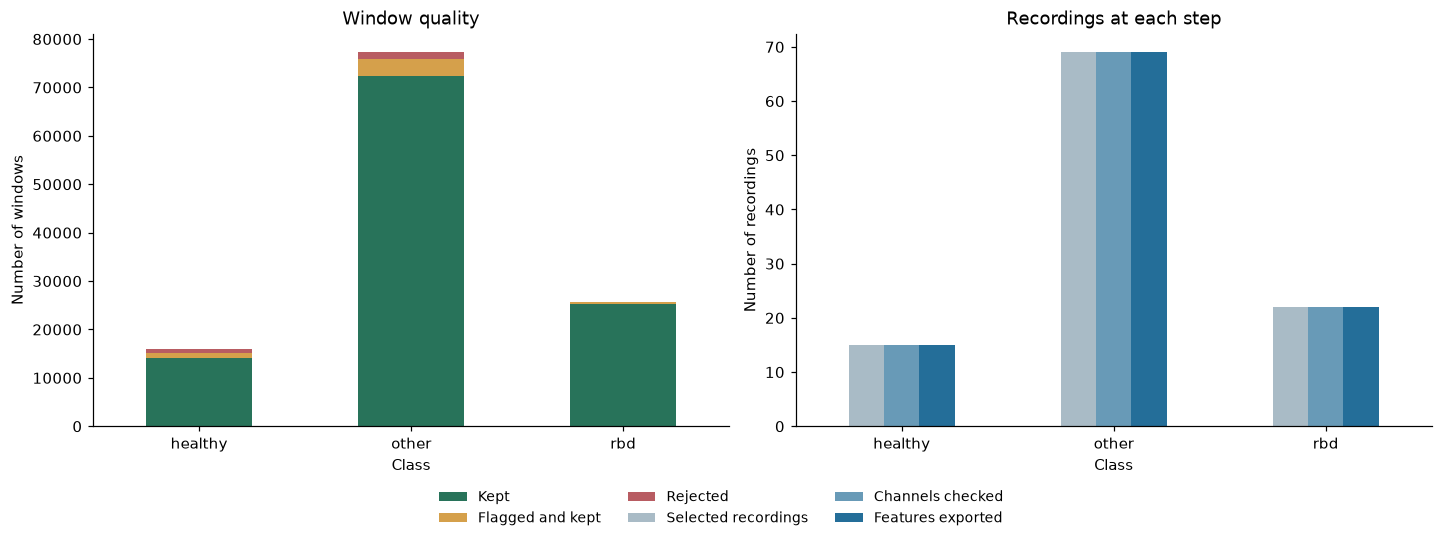

,Selected recordings,Channels checked,Features exported
class_name,,,
healthy,15,15,15
other,69,69,69
rbd,22,22,22


quality_status,keep,flag,exclude
class_name,,,
healthy,14072,1099,874
other,72450,3531,1279
rbd,25317,333,11


In [19]:
baseline_windows = window_tables["baseline"]
quality_counts = pd.crosstab(baseline_windows["class_name"], baseline_windows["quality_status"]).reindex(columns=["keep", "flag", "exclude"], fill_value=0)
coverage = pd.DataFrame({
    "Selected recordings": mapping.groupby("class_name").size(),
    "Channels checked": inventory[inventory["status"].eq("ready")].groupby("class_name").size(),
    "Features exported": recording_tables["baseline"].groupby("class_name").size(),
}).fillna(0).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
quality_counts.plot.bar(stacked=True, ax=axes[0], color=["#28735a", "#d5a04b", "#b85c62"], legend=False, rot=0)
coverage.plot.bar(ax=axes[1], color=["#a9bbc6", "#689ab7", "#246e99"], legend=False, rot=0)
axes[0].set(title="Window quality", xlabel="Class", ylabel="Number of windows")
axes[1].set(title="Recordings at each step", xlabel="Class", ylabel="Number of recordings")
handles_left, labels_left = axes[0].get_legend_handles_labels()
handles_right, labels_right = axes[1].get_legend_handles_labels()
quality_labels = {"keep": "Kept", "flag": "Flagged and kept", "exclude": "Rejected"}
fig.legend(handles_left + handles_right, [quality_labels[label] for label in labels_left] + labels_right, loc="outside lower center", ncols=3, fontsize=9)
fig.savefig(FIGURE_DIR / "preprocessing_quality_summary.png", bbox_inches="tight", pad_inches=0.18)
plt.show()
display(coverage)
display(quality_counts)
missing_exports = mapping.loc[~mapping["record_id"].isin(recording_tables["baseline"]["record_id"]), ["record_id", "class_name"]]
if not missing_exports.empty:
    display(missing_exports)